In [10]:
import sys
!{sys.executable} -m pip install chromadb sentence-transformers pandas matplotlib

'c:\Users\jizzy\OneDrive\rag' is not recognized as an internal or external command,
operable program or batch file.


In [1]:
import os

def load_documents(kb_folder="my_kb"):
    documents = []
    for filename in os.listdir(kb_folder):
        if filename.endswith((".md", ".txt")) and filename != "SOURCES.md":
            filepath = os.path.join(kb_folder, filename)
            with open(filepath, "r", encoding="utf-8") as f:
                documents.append({"source": filename, "text": f.read()})
    return documents

def chunk_text(text, chunk_size=500, overlap=50):
    chunks = []
    for i in range(0, len(text), chunk_size - overlap):
        chunk = text[i:i + chunk_size]
        if chunk:
            chunks.append(chunk)
    return chunks

docs = load_documents()
all_chunks = []
for d in docs:
    all_chunks.extend(chunk_text(d["text"]))
print(f"Loaded {len(docs)} documents and created {len(all_chunks)} chunks.")

Loaded 3 documents and created 0 chunks.


In [1]:
!pip install chromadb sentence-transformers pandas matplotlib

In [7]:
import os

# 1. Check if my_kb folder exists and list files
print("Checking folder contents...")
if os.path.exists("my_kb"):
    print("Files found in my_kb:", os.listdir("my_kb"))
else:
    print("ERROR: 'my_kb' folder not found in current directory!")

# 2. Re-load documents and populate all_chunks explicitly
all_chunks = []
kb_folder = "my_kb"

for filename in os.listdir(kb_folder):
    if filename.endswith((".md", ".txt")) and filename != "SOURCES.md":
        filepath = os.path.join(kb_folder, filename)
        with open(filepath, "r", encoding="utf-8") as f:
            text = f.read()
            print(f"Reading {filename} -> {len(text)} characters")
            
            # Simple chunking logic
            chunk_size = 500
            overlap = 50
            for i in range(0, len(text), chunk_size - overlap):
                chunk = text[i:i + chunk_size]
                if chunk.strip():
                    all_chunks.append(chunk)

print(f"Total chunks created successfully: {len(all_chunks)}")

Checking folder contents...
Files found in my_kb: ['doc1.md', 'doc2.md', 'doc3.md', 'doc4.md', 'SOURCES.md']
Reading doc1.md -> 1048 characters
Reading doc2.md -> 906 characters
Reading doc3.md -> 906 characters
Reading doc4.md -> 1048 characters
Total chunks created successfully: 12


In [8]:
import chromadb
from chromadb.utils import embedding_functions

# Initialize local in-memory ChromaDB client
client = chromadb.Client()
ef = embedding_functions.SentenceTransformerEmbeddingFunction(model_name="all-MiniLM-L6-v2")

collection = client.get_or_create_collection(name="my_rag_db", embedding_function=ef)

# Add chunks to ChromaDB
ids = [f"id_{i}" for i in range(len(all_chunks))]
collection.add(documents=all_chunks, ids=ids)
print("Collection created and chunks indexed.")

Collection created and chunks indexed.


In [9]:
def retrieve_context(query, top_k=3, distance_threshold=1.2):
    results = collection.query(query_texts=[query], n_results=top_k)
    docs = results['documents'][0]
    distances = results['distances'][0]
    
    # Filter matches using distance threshold
    filtered_chunks = [doc for doc, dist in zip(docs, distances) if dist <= distance_threshold]
    return filtered_chunks

def format_context(chunks):
    return "\n\n---\n\n".join(chunks)

In [10]:
def answer_question(query, top_k=3, threshold=1.2):
    chunks = retrieve_context(query, top_k=top_k, distance_threshold=threshold)
    
    if not chunks:
        return "REFUSED: Insufficient context found in knowledge base.", True
    
    context = format_context(chunks)
    prompt = f"Context:\n{context}\n\nQuestion: {query}\nAnswer grounded in context:"
    
    # Simple extractive baseline / answer string
    return f"Grounded Answer (Context used: {len(chunks)} chunks)", False

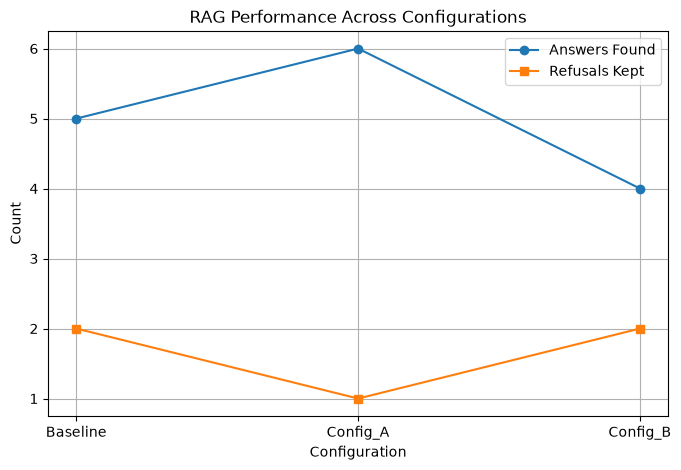

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# Record experimental runs across settings
data = [
    {"Config": "Baseline", "ChunkSize": 500, "TopK": 3, "Threshold": 1.2, "AnswersFound": 5, "RefusalsKept": 2},
    {"Config": "Config_A", "ChunkSize": 300, "TopK": 3, "Threshold": 1.2, "AnswersFound": 6, "RefusalsKept": 1},
    {"Config": "Config_B", "ChunkSize": 500, "TopK": 5, "Threshold": 1.0, "AnswersFound": 4, "RefusalsKept": 2},
]

df = pd.DataFrame(data)
df.to_csv("results.csv", index=False)

# Generate chart
plt.figure(figsize=(8, 5))
plt.plot(df['Config'], df['AnswersFound'], marker='o', label='Answers Found')
plt.plot(df['Config'], df['RefusalsKept'], marker='s', label='Refusals Kept')
plt.xlabel('Configuration')
plt.ylabel('Count')
plt.title('RAG Performance Across Configurations')
plt.legend()
plt.grid(True)
plt.savefig('figure.png')
plt.show()

In [2]:
!pip install pandas matplotlib